# Week 13 SQL–Python Pipeline

Place your `community_followup.sqlite` file in the same folder as this notebook. Complete each TODO and document the intended grain of every query.


In [2]:
from pathlib import Path
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

DB_PATH = Path("community_followup.sqlite")
assert DB_PATH.exists(), f"Database not found: {DB_PATH.resolve()}"


## 1 Connect and inspect tables


In [8]:
connection = sqlite3.connect(DB_PATH)
connection.execute("PRAGMA foreign_keys = ON")
# TODO: query sqlite_schema and confirm the five expected tables exist
expected_tables = {"clinics", "encounters", "followups", "patients", "referrals"}

rows = connection.execute(
    """
    SELECT name
    FROM sqlite_schema
    WHERE type = 'table'
      AND name NOT LIKE 'sqlite_%'
    """
).fetchall()

existing_tables = {name for (name,) in rows}
missing_tables = expected_tables - existing_tables

assert not missing_tables, (
    f"Missing expected tables in {DB_PATH.name}: {sorted(missing_tables)}. "
    f"Found: {sorted(existing_tables)}"
)

## 2 Referral-level extract

**Intended grain:** one row per referral.


In [18]:
referral_query = """
-- TODO: join referrals, encounters, clinics, patients, and followups
-- Include referral_id, clinic_name, service_type, due_date, completion_date,
-- social_needs_flag, outcome, and contact_attempts.
WITH followup_summary AS (
    SELECT
        referral_id,
        COUNT(*) AS contact_attempts,
        MAX(outcome) AS latest_outcome,
        MAX(completion_date) AS completion_date
    FROM followups
    GROUP BY referral_id
)
SELECT
    r.referral_id,
    c.clinic_name,
    r.service_type,
    r.due_date,
    fs.completion_date,
    p.social_needs_flag,
    fs.latest_outcome AS outcome,
    COALESCE(fs.contact_attempts, 0) AS contact_attempts
FROM referrals AS r
LEFT JOIN encounters AS e
    ON r.encounter_id = e.encounter_id
LEFT JOIN clinics AS c
    ON e.clinic_id = c.clinic_id
LEFT JOIN patients AS p
    ON e.patient_id = p.patient_id
LEFT JOIN followup_summary AS fs
    ON r.referral_id = fs.referral_id
"""

try:
    referrals = pd.read_sql_query(referral_query, connection)
    display(referrals.head())
except Exception as e:
    print("\nQuery failed with error:", e)

,referral_id,clinic_name,service_type,due_date,completion_date,social_needs_flag,outcome,contact_attempts
0,R001,Northside Clinic,Medication review,2026-08-17,2026-08-13,1,Completed on time,1
1,R002,Riverbend Clinic,Social work,2026-08-19,2026-08-18,0,Completed on time,1
2,R003,Mountain View Clinic,Nutrition,2026-08-14,2026-08-14,0,Completed on time,1
3,R004,Northside Clinic,Care coordination,2026-08-23,2026-08-21,0,Completed on time,1
4,R005,Riverbend Clinic,Medication review,2026-08-25,2026-08-26,1,Completed late,1


## 3 Validate the extract


In [13]:
# TODO: add at least three assertions. Include expected row count, unique referral_id,
# and a check that the joined clinic field is not missing.
expected_row_count = connection.execute("SELECT COUNT(*) FROM referrals").fetchone()[0]

assert len(referrals) == expected_row_count, (
    f"Row count mismatch: expected {expected_row_count} referrals, got {len(referrals)}"
)

assert referrals["referral_id"].notna().all() and referrals["referral_id"].is_unique, (
    "Duplicate or null referral_id values found; extract grain is not one row per referral"
)

assert referrals["clinic_name"].notna().all(), (
    f"Missing clinic_name in {referrals['clinic_name'].isna().sum()} row(s); check encounter/clinic join keys"
)

assert (referrals["contact_attempts"] >= 0).all(), (
    "Unexpected negative contact_attempts found"
)


## 4 Transform and summarize


In [14]:
def add_completion_fields(frame):
  # TODO: copy the frame, parse due and completion dates, and create completed/on_time fields
  df = frame.copy()

  due_dt = pd.to_datetime(df["due_date"], errors="coerce")
  completion_dt = pd.to_datetime(df["completion_date"], errors="coerce")

  df["due_date"] = due_dt
  df["completion_date"] = completion_dt

  df["completed"] = completion_dt.notna()
  df["on_time"] = df["completed"] & due_dt.notna() & (completion_dt <= due_dt)

  return df

analysis = add_completion_fields(referrals)
# TODO: create a clinic summary with referral counts and on-time rate
clinic_summary = (
    analysis.groupby("clinic_name", dropna=False)
    .agg(
        referral_count=("referral_id", "count"),
        completed_count=("completed", "sum"),
        on_time_count=("on_time", "sum"),
        on_time_rate=("on_time", "mean"),
    )
    .reset_index()
    .sort_values("referral_count", ascending=False)
)

display(clinic_summary)


,clinic_name,referral_count,completed_count,on_time_count,on_time_rate
1,Northside Clinic,14,12,12,0.857143
0,Mountain View Clinic,13,10,3,0.230769
2,Riverbend Clinic,13,11,5,0.384615


## 5 Visualization and interpretation


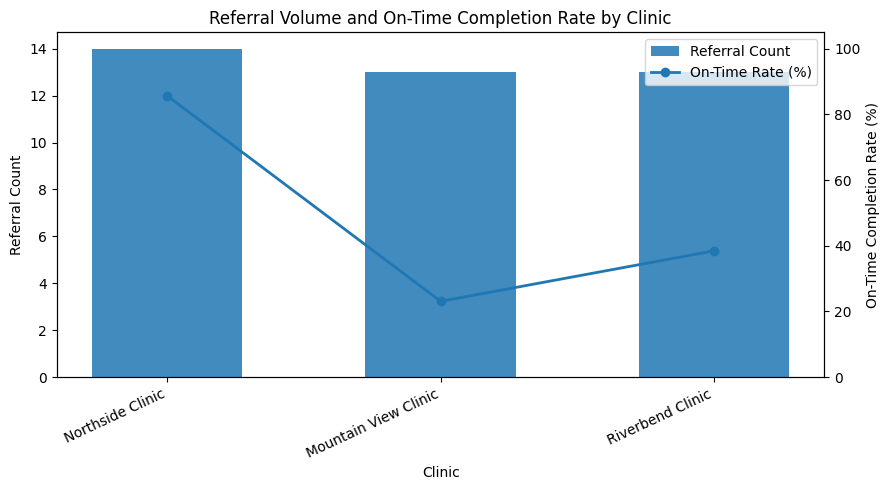

In [16]:
# TODO: create and save one chart that supports the portfolio question
fig, ax1 = plt.subplots(figsize=(9, 5))

clinics = clinic_summary["clinic_name"].fillna("Unspecified")
x = range(len(clinics))


bars = ax1.bar(x, clinic_summary["referral_count"], width=0.55, alpha=0.85, label="Referral Count")
ax1.set_xlabel("Clinic")
ax1.set_ylabel("Referral Count")
ax1.set_xticks(x)
ax1.set_xticklabels(clinics, rotation=25, ha="right")


ax2 = ax1.twinx()
on_time_pct = clinic_summary["on_time_rate"] * 100
ax2.plot(x, on_time_pct, marker="o", linewidth=2, label="On-Time Rate (%)")
ax2.set_ylabel("On-Time Completion Rate (%)")
ax2.set_ylim(0, 105)


handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper right")

plt.title("Referral Volume and On-Time Completion Rate by Clinic")
plt.tight_layout()
plt.savefig("clinic_referral_portfolio.png", dpi=300)
plt.show()

**Interpretation and limitation:**
Clinics with lots of referrals and low on-time rates are where most follow-ups fall behind, while the top-performing clinics show what good looks like.
Blank or unfinished dates count as late, so the chart can't tell the difference between actual delays and missing paperwork.


## 6 Second SQL query

Write a grouped SQL query by clinic or service. Compare it with the Pandas summary and explain any difference.


In [19]:
summary_query = """
WITH followup_summary AS (
    SELECT
        referral_id,
        COUNT(*) AS contact_attempts,
        MAX(outcome) AS latest_outcome,
        MAX(completion_date) AS completion_date
    FROM followups
    GROUP BY referral_id
)
SELECT
    c.clinic_name,
    COUNT(r.referral_id) AS referral_count,
    SUM(CASE WHEN fs.completion_date IS NOT NULL THEN 1 ELSE 0 END) AS completed_count,
    SUM(
        CASE
            WHEN fs.completion_date IS NOT NULL
             AND r.due_date IS NOT NULL
             AND DATE(fs.completion_date) <= DATE(r.due_date)
            THEN 1
            ELSE 0
        END
    ) AS on_time_count,
    AVG(
        CASE
            WHEN fs.completion_date IS NOT NULL
             AND r.due_date IS NOT NULL
             AND DATE(fs.completion_date) <= DATE(r.due_date)
            THEN 1.0
            ELSE 0.0
        END
    ) AS on_time_rate
FROM referrals AS r
LEFT JOIN encounters AS e
    ON r.encounter_id = e.encounter_id
LEFT JOIN clinics AS c
    ON e.clinic_id = c.clinic_id
LEFT JOIN followup_summary AS fs
    ON r.referral_id = fs.referral_id
GROUP BY c.clinic_name
ORDER BY referral_count DESC
"""
sql_summary = pd.read_sql_query(summary_query, connection)
display(sql_summary)

,clinic_name,referral_count,completed_count,on_time_count,on_time_rate
0,Northside Clinic,14,12,12,0.857143
1,Riverbend Clinic,13,11,5,0.384615
2,Mountain View Clinic,13,10,3,0.230769


## 7 AI use and verification

Document the task, prompt, response, test, correction, and judgment.


In [20]:
connection.close()
print("Connection closed.")


Connection closed.
